<a href="https://colab.research.google.com/github/mohitkumar64/PyTorch-/blob/main/01_learning_pytorach.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import matplotlib.pyplot as plt
from torch import nn

In [ ]:
torch.cuda.is_available()

False

##Importing data or getting data

In [ ]:
 #create a know parameters
weight = 0.7
bias = 0.3


start = 0
end = 1
step = 0.02
X = torch.arange(start,end,step).unsqueeze(dim=1)
y = weight * X + bias


X[:10] , y[:10]

(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560],
         [0.3700],
         [0.3840],
         [0.3980],
         [0.4120],
         [0.4260]]))

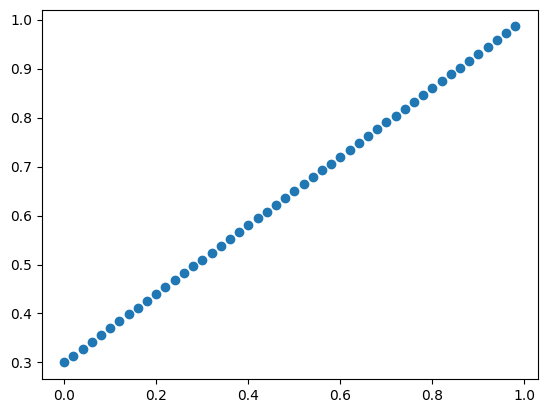

In [ ]:
plt.scatter(X[:,0],y[:,0])

In [ ]:
# splitting the data into train valid and test set
train_split = int(0.8 * len(X));
x_train , y_train = X[:train_split , 0] , y[0 :train_split , 0]
x_test , y_test = X[train_split : , 0] , y[train_split : , 0]

len(x_train) , len(x_test)

(40, 10)

In [ ]:
!pip install plotly


In [ ]:
import plotly.express as px

In [ ]:
len(X)

50

In [ ]:
px.scatter(x=X[:,0], y = y[: , 0])

In [ ]:
import plotly.graph_objects as go
def plot_pred(y_preds= None):
  fig = go.Figure()
  fig.add_trace(go.Scatter(x=x_train, y = y_train , name='train data'))
  fig.add_trace(go.Scatter(x=x_test, y = y_test ,  name='test data') )
  if(y_preds is not None):
    fig.add_trace(go.Scatter(x=x_test, y = y_preds ,  name='pred data'))

  fig.show()

plot_pred()

In [ ]:
class LinearRegressionModel(nn.Module):

  def __init__(self):
    super().__init__()
    self.weights = nn.Parameter(torch.randn(1,
                                            requires_grad=True,
                                            dtype=torch.float)
                                            )


    self.bias = nn.Parameter(torch.randn(1,
                                            requires_grad=True,
                                            dtype=torch.float)
                                            )
  def forward(self , x:torch.Tensor)-> torch.Tensor:
    return self.weights * x + self.bias #linear regression formula

In [ ]:
  ## torch.utils.data.Datset and Dataloader
  ## torchmetrics

In [ ]:
# checking the contents of out pytorch model

In [ ]:
torch.manual_seed(42)
model_0 = LinearRegressionModel()

## parameter values
list(model_0.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [ ]:
## list named Parameterts
model_0.state_dict()

OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

In [ ]:
## making predi using torch.inference_mode()

with torch.inference_mode():
  y_preds = model_0(x_test)


y_preds
plot_pred(y_preds)

In [ ]:
from sklearn.metrics import root_mean_squared_error

rmse = root_mean_squared_error(y_test, y_preds)
rmse

0.49497636346580104

In [ ]:
#train

In [ ]:
## setup a losss function
loss_fn = nn.L1Loss()


## setup an optimizer
optimizer = torch.optim.SGD(params = model_0.parameters(),
                            lr = 0.001)

## learning rate possibly most used hyperparameter (set by us )


0. loop thorugh the data
1. forward pass
2. cal the loss
3. optimizer zero grad
4. loss backward - move backwards (backpropafation)
5.optimizer step

In [ ]:

 # an epoch is  one sucess loop though data
epochs = 1000

# loop through the data
for epoch in range(epochs):
  # set the model to training mode
  model_0.train()

  #1
  y_pred = model_0(x_train)
  #2
  loss = loss_fn(y_pred , y_train)

  #3
  optimizer.zero_grad()

  #4
  loss.backward()

  #5
  optimizer.step()


  model_0.eval() ## turns off gradient tracking

  if epoch % 100 == 0:
    with torch.inference_mode():
      y_preds = model_0(x_test)

    y_preds
    # plot_pred(y_preds)

    print("updated parameter " , model_0.state_dict())
    rmse = loss_fn(y_test, y_preds)
    print("loss for " , epoch , " is " , rmse)


updated parameter  OrderedDict({'weights': tensor([0.3371]), 'bias': tensor([0.1298])})
loss for  0  is  tensor(0.4932)
updated parameter  OrderedDict({'weights': tensor([0.3761]), 'bias': tensor([0.2298])})
loss for  100  is  tensor(0.3585)
updated parameter  OrderedDict({'weights': tensor([0.4150]), 'bias': tensor([0.3257])})
loss for  200  is  tensor(0.2280)
updated parameter  OrderedDict({'weights': tensor([0.4485]), 'bias': tensor([0.3730])})
loss for  300  is  tensor(0.1509)
updated parameter  OrderedDict({'weights': tensor([0.4730]), 'bias': tensor([0.3855])})
loss for  400  is  tensor(0.1166)
updated parameter  OrderedDict({'weights': tensor([0.4924]), 'bias': tensor([0.3839])})
loss for  500  is  tensor(0.1009)
updated parameter  OrderedDict({'weights': tensor([0.5104]), 'bias': tensor([0.3789])})
loss for  600  is  tensor(0.0899)
updated parameter  OrderedDict({'weights': tensor([0.5277]), 'bias': tensor([0.3724])})
loss for  700  is  tensor(0.0810)
updated parameter  Ordered

saving a model in pytorch
there are three main method i should know about for saving and loading

1. torch.save()
2. torch.load()
3. `torch.nn.Module.load_state_dict()`

In [ ]:
from pathlib import Path

In [ ]:
!mkdir model

In [ ]:
model_path = Path("models")
model_path.mkdir(parents = True , exist_ok=True)

model_name = "01_pytorch.pth"
model_save_path = model_path / model_name


In [ ]:
torch.save(model_0.state_dict(), model_save_path)